<a href="https://colab.research.google.com/github/kinantirizky/Analisis-Deret-Waktu-/blob/main/Tugas_Praktikum_Minggu_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# KELOMPOK 5
- Fenniya Angel Lee M0501261094
- Husnul Amira M0501251059
- Kinanti Rizky Pangestutik M0501251038

#**SOAL**
1. Buatlah simulasi deret waktu (parameter yang digunakan bebas, tetapi berbeda dengan contoh yag sudah digunakan di atas) menggunakan seed 25xx, dimana xx adalah jumlah dua digit terakhir NIM anggota kelompok (misal NIM: 09 dan 28, maka seed yang digunakan 2537 . Lakukan pendugaan parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum:
Kelompok 1: ARIMA (0,0,1) dan ARIMA (2,2,2)

Kelompok 2: ARIMA (2,0,1) dan ARIMA (1,1,1)

Kelompok 3: ARIMA (1,0,1) dan ARIMA (1,1,2)

Kelompok 4: ARIMA (1,0,0) dan ARIMA (2,2,1)

Kelompok 5: ARIMA (2,0,0) dan ARIMA (2,1,1)

Kelompok 6: ARIMA (1,0,2) dan ARIMA (1,2,1)

Kelompok 7: ARIMA (0,0,2) dan ARIMA (1,2,2)

Kelompok 8: ARIMA (1,0,2) dan ARIMA (2,1,2)

Kelompok 9: ARIMA (2,0,2) dan ARIMA (1,2,1)

2. Ulangi langkah no.1 sebanyak 30 ulangan. Hitunglah bias dan ragam dari penduga parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum yang diperoleh dari 30 ulangan tersebut. Dan buatlah boxplot untuk memvisualisasikan bias dan ragam tersebut. Interpretasikan boxpot yang diperoleh

Kelompok 5 : ARIMA (2,0,0) dan ARIMA (2,1,1) dengan nim 94+59+38=191 jadi 2591

# JAWABAN

# Nomor 1 ARIMA (2,0,0)

Model ARIMA(2,0,0) ini menggunakan parameter AR yaitu $\phi_1=0.6$ dan $\phi_2=-0.2$:

$$Y_t = 0.6 Y_{t-1} - 0.2 Y_{t-2} + \varepsilon_t, \quad \varepsilon_t\sim N(0,1).$$

In [ ]:
!pip install rpy2

In [ ]:
%load_ext rpy2.ipython

**Tentukan parameter dan periksa stasioneritas**

In [ ]:
%%R

phi1 <- 0.6
phi2 <- -0.2
n <- 300

kriteria1 <- abs(phi2) < 1
kriteria2 <- (phi2 + phi1) < 1
kriteria3 <- (phi2 - phi1) < 1

hasil_kriteria <- data.frame(
  Kriteria = c(
    "|phi2| < 1",
    "phi2 + phi1 < 1",
    "phi2 - phi1 < 1"
  ),
  Nilai = c(
    abs(phi2),
    phi2 + phi1,
    phi2 - phi1
  ),
  Memenuhi = c(
    kriteria1,
    kriteria2,
    kriteria3
  )
)

print(hasil_kriteria, row.names = FALSE)

        Kriteria Nilai Memenuhi
      |phi2| < 1   0.2     TRUE
 phi2 + phi1 < 1   0.4     TRUE
 phi2 - phi1 < 1  -0.8     TRUE


Dari hasil sistem persamaan pada kriteria, parameter yang digunakan yaitu $\phi_1 = 0.6$ dan $\phi_2 = -0.2$.

Ketiga syarat stasioneritas untuk model AR(2) bernilai TRUE:
- $\vert{}\phi_2\vert{} = \vert{}-0.2\vert{} = 0.2 < 1$
- $\phi_2 + \phi_1 = -0.2 + 0.6 = 0.4 - < 1$
- $\phi_2 - \phi_1 = -0.2 - 0.6 = -0.8 < 1$

Karena semua syarat terpenuhi, proses AR(2) ini dipastikan stasioner. Datanya nggak bakal naik/turun berlebihan (explode) dan variansnya tetap terkontrol sepanjang waktu.

**Simulasi satu ulangan dengan seed 2591**

Jumlah pengamatan: 300 
Time Series:
Start = 1 
End = 10 
Frequency = 1 
 [1] -0.01020952  1.80000981  0.65847943  0.24765135  1.78591067  2.12313349
 [7]  1.15105559 -2.18948225 -2.50152471 -0.65888287
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-2.89669 -0.74379  0.06673  0.04030  0.83461  3.86714 


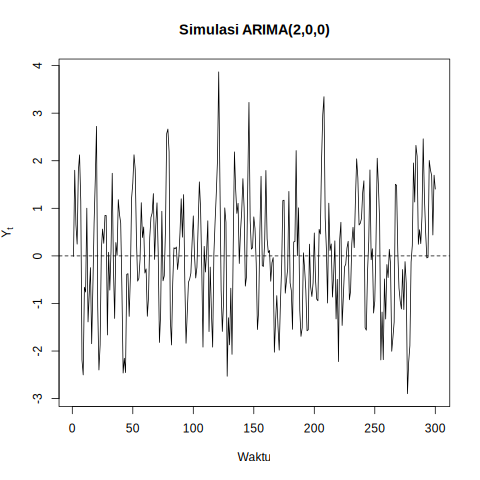

In [ ]:
%%R

set.seed(2591)

ar2 <- arima.sim(
  list(
    order = c(2, 0, 0),
    ar = c(phi1, phi2)
  ),
  n = n
)

# Menampilkan data dan ringkasan
cat("Jumlah pengamatan:", length(ar2), "\n")
print(head(ar2, 10))
print(summary(ar2))

# Plot deret waktu
plot(
  ar2,
  type = "l",
  main = "Simulasi ARIMA(2,0,0)",
  xlab = "Waktu",
  ylab = expression(Y[t])
)

abline(h = 0, lty = 2)




Nilai Mean ($0.04030$) dan Median ($0.06673$) berada sangat dekat dengan angka $0$. Ini sesuai dengan nilai harapan teoritis model AR(2) tanpa konstanta yang berpusat di rata-rata nol. Rentang data berada di antara $-2.89669$ (minimum) dan $3.86714$ (maksimum), dengan sebaran kuartil 1 ($-0.74379$) dan kuartil 3 ($0.83461$) yang simetris mengelilingi nol.

Berdasarkan grafik simulasi ARIMA(2,0,0), pergerakan nilai $Y_t$ secara konsisten berfluktuasi mengelilingi garis nol (garis putus-putus) tanpa membentuk tren naik atau turun jangka panjang. Lebar simpangan data dari indeks $t=1$ sampai $t=300$ relatif seragam dan konstan. Secara visual, proses simulasi ARIMA(2,0,0) yang dibangun terbukti stasioner.

**Pendugaan LS untuk satu ulangan**

In [ ]:
%%R

# Pendugaan Least Squares (OLS)
hasil_LS <- ar(
  ar2,
  order.max = 2,
  AIC = FALSE,
  method = "ols"
)

print(hasil_LS)



Call:
ar(x = ar2, order.max = 2, method = "ols", AIC = FALSE)

Coefficients:
      1        2  
 0.6114  -0.1910  

Intercept: -0.004976 (0.05982) 

Order selected 2  sigma^2 estimated as  1.066


Pendugaan berbasis minimasi jumlah kuadrat sisaan menghasilkan $\hat{\phi}_1 = 0.6114$ dan $\hat{\phi}_2 = -0.1910$. Nilai intercept sebesar $-0.004976$ dengan standard error $0.05982$ menunjukkan bahwa rerata proses secara statistik tidak berbeda secara signifikan dari nol. Ragam galat ditemukan sebesar $1.066$, yang menggambarkan besarnya variansi sisaan dari model LS.

**Pendugaan MLE untuk satu ulangan**

In [ ]:
%%R

# Pendugaan Maximum Likelihood
hasil_MLE <- ar(
  ar2,
  order.max = 2,
  AIC = FALSE,
  method = "mle"
)

print(hasil_MLE)


Call:
ar(x = ar2, order.max = 2, method = "mle", AIC = FALSE)

Coefficients:
      1        2  
 0.6101  -0.1915  

Order selected 2  sigma^2 estimated as  1.069


Pendugaan berbasis fungsi maximum likelihood menghasilkan $\hat{\phi}_1 = 0.6101$ dan $\hat{\phi}_2 = -0.1915$. Ragam galat ditemukan sebesar $1.069$, sedikit lebih tinggi dibandingkan hasil pendugaan LS.

**Bandingkan hasil satu ulangan**

In [ ]:
%%R

# Perbandingan dengan parameter asli
perbandingan_satu <- data.frame(
  Parameter = c("AR(1)", "AR(2)"),
  Parameter_Asli = c(phi1, phi2),
  LS = as.numeric(hasil_LS$ar),
  MLE = as.numeric(hasil_MLE$ar)
)

perbandingan_satu$Penyimpangan_LS <-
  perbandingan_satu$LS -
  perbandingan_satu$Parameter_Asli

perbandingan_satu$Penyimpangan_MLE <-
  perbandingan_satu$MLE -
  perbandingan_satu$Parameter_Asli

print(perbandingan_satu, row.names = FALSE)


 Parameter Parameter_Asli         LS        MLE Penyimpangan_LS
     AR(1)            0.6  0.6113579  0.6101009     0.011357938
     AR(2)           -0.2 -0.1910087 -0.1915421     0.008991292
 Penyimpangan_MLE
      0.010100924
      0.008457867


Kedua metode berhasil mendekati nilai parameter sebenarnya ($\phi_1 = 0.6$ dan $\phi_2 = -0.2$) dengan sangat baik.
- Parameter $\phi_1$: Metode MLE memiliki penyimpangan sebesar $0.0101$, lebih kecil dibandingkan LS yang sebesar $0.0114$.
-  Parameter $\phi_2$: Metode MLE juga mencatatkan penyimpangan lebih kecil ($0.0085$) dibandingkan LS ($0.0090$).
Untuk satu simulasi ulangan ini, metode MLE sedikit lebih unggul dan presisi dibandingkan LS karena menghasilkan nilai penyimpangan (galat pendugaan) yang lebih rendah pada kedua parameter.


# Nomor 1 ARIMA (2,1,1)

Model ini menggunakan parameter AR yang sama dengan ARIMA(2,0,0), yaitu $\phi_1=0.6$ dan $\phi_2=-0.2$, dengan tambahan parameter MA $\theta_1=0.35$. Model tanpa drift:

$$\Delta Y_t = 0.6\Delta Y_{t-1} - 0.2\Delta Y_{t-2} + \varepsilon_t + 0.35\varepsilon_{t-1}, \quad \varepsilon_t\sim N(0,1).$$

Untuk memperoleh **300 pengamatan pada level** $Y_t$, kita membangkitkan 299 nilai proses ARMA dan menetapkan $Y_1=0$. Pendugaan menggunakan *Conditional Sum of Squares* (CSS, implementasi kuadrat terkecil untuk ARIMA dengan MA) dan *Maximum Likelihood* (ML). Ini berbeda dari fungsi `ar(..., method="ols")` yang digunakan pada ARIMA(2,0,0) karena model ini mengandung komponen MA.

In [ ]:
%%R
# Spesifikasi ARIMA(2,1,1) dan pemeriksaan akar
phi_211 <- c(0.6, -0.2)
theta_211 <- 0.35
n_211 <- 300

akar_ar_211 <- polyroot(c(1, -phi_211))
akar_ma_211 <- polyroot(c(1, theta_211))

cat("Modulus akar AR:", round(Mod(akar_ar_211), 4), "\n")
cat("Modulus akar MA:", round(Mod(akar_ma_211), 4), "\n")
stopifnot(all(Mod(akar_ar_211) > 1),
          all(Mod(akar_ma_211) > 1))


Modulus akar AR: 2.2361 2.2361 
Modulus akar MA: 2.8571 


Nilai modulus akar AR ($2.2361 > 1$) dan MA ($2.8571 > 1$) keduanya berada di luar lingkaran satuan. Ini mengonfirmasi bahwa setelah dilakukan diferensi pertama ($d=1$), deret ter-diferensi memenuhi syarat stasioner dan invertibel.

**Simulasi ARIMA(2,1,1) satu kali dengan seed 2591 dan $n=300$**

Jumlah observasi pada level: 300 
Time Series:
Start = 1 
End = 10 
Frequency = 1 
 [1]  0.000000  1.796543  3.085110  3.563258  5.435847  8.184044 10.078193
 [8]  8.291579  5.023736  3.489320
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
-14.389  -1.464   3.180   3.653   8.336  20.185 


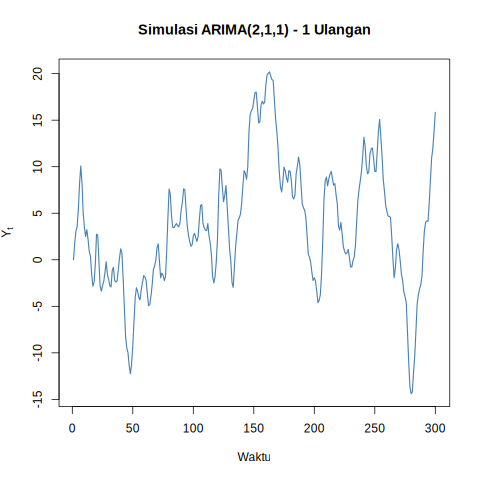

In [ ]:
%%R
set.seed(2591)

# Bangkitkan proses beda pertama W_t ~ ARMA(2,1) sebanyak 299 nilai
w_211 <- arima.sim(
  model = list(order = c(2, 0, 1), ar = phi_211, ma = theta_211),
  n = n_211 - 1,
  sd = 1
)

# Integrasi sekali. Y_1 = 0 sehingga total 300 pengamatan
arima211 <- ts(c(0, cumsum(as.numeric(w_211))))

cat("Jumlah observasi pada level:", length(arima211), "\n")
print(head(arima211, 10))
print(summary(arima211))

plot(arima211, type = "l", col = "steelblue", lwd = 1.5,
     main = "Simulasi ARIMA(2,1,1) - 1 Ulangan",
     xlab = "Waktu", ylab = expression(Y[t]))


Nilai Mean ($3.653$) dan Median ($3.180$) tidak berpusat di nol, dengan rentang sebaran data yang sangat lebar mulai dari nilai Min ($-14.389$) hingga Max ($20.185$).

Plot memperlihatkan pergerakan acak berkelana (wandering) serta membentuk tren lokal naik dan turun jangka panjang tanpa ada kecenderungan kembali ke garis nol. Pola visual ini mengonfirmasi bahwa deret bersifat non-stasioner pada level.

**Perbandingan ARIMA(2,0,0) vs ARIMA(2,1,1) pada Satu Ulangan**
- ARIMA(2,0,0) bersifat stasioner pada level dengan fluktuasi yang konstan mengelilingi rata-rata nol, sedangkan ARIMA(2,1,1) bersifat non-stasioner pada level akibat adanya integrasi pembedaan pertama ($d=1$).
- Rerata ARIMA(2,0,0) berada sangat dekat dengan nilai harapan teoritisnya di angka nol ($0.04030$), sementara rerata ARIMA(2,1,1) bergeser signifikan ($3.653$).
- ARIMA(2,0,0) memiliki rentang fluktuasi yang relatif sempit dan terkontrol ($-2.89669$ hingga $3.86714$), sedangkan ARIMA(2,1,1) memiliki rentang pergerakan yang jauh lebih lebar ($-14.389$ hingga $20.185$) akibat akumulasi komponen random walk.

**Pendugaan parameter LS (CSS) dan MLE untuk ARIMA(2,1,1)**

In [ ]:
%%R
# Pendugaan LS untuk model dengan MA: conditional sum of squares
hasil_LS_211 <- stats::arima(
  arima211, order = c(2, 1, 1),
  include.mean = FALSE, method = "CSS",
  optim.control = list(maxit = 1000)
)

# Pendugaan MLE Gaussian (exact likelihood)
hasil_MLE_211 <- stats::arima(
  arima211, order = c(2, 1, 1),
  include.mean = FALSE, method = "ML",
  optim.control = list(maxit = 1000)
)

cat("\nRingkasan LS (CSS):\n")
print(hasil_LS_211)
cat("\nRingkasan MLE:\n")
print(hasil_MLE_211)
cat("\nKode konvergensi LS:", hasil_LS_211$code, "\n")
cat("Kode konvergensi MLE:", hasil_MLE_211$code, "\n")
if (hasil_LS_211$code != 0 || hasil_MLE_211$code != 0)
  warning("Salah satu optimisasi belum mencapai status konvergensi 0")



Ringkasan LS (CSS):

Call:
stats::arima(x = arima211, order = c(2, 1, 1), include.mean = FALSE, method = "CSS", 
    optim.control = list(maxit = 1000))

Coefficients:
         ar1      ar2     ma1
      0.8405  -0.3608  0.1083
s.e.  0.1082   0.0836  0.1105

sigma^2 estimated as 1.053:  part log likelihood = -431.99

Ringkasan MLE:

Call:
stats::arima(x = arima211, order = c(2, 1, 1), include.mean = FALSE, method = "ML", 
    optim.control = list(maxit = 1000))

Coefficients:
         ar1      ar2     ma1
      0.8412  -0.3603  0.1077
s.e.  0.1081   0.0837  0.1106

sigma^2 estimated as 1.051:  log likelihood = -432.19,  aic = 872.38

Kode konvergensi LS: 0 
Kode konvergensi MLE: 0 


Metode LS (CSS) dan MLE sama-sama menghasilkan kode konvergensi 0, yang menandakan algoritma optimasi berhasil konvergen sempurna tanpa kendala numerik pada simulasi satu ulangan ini.

**Perbandingan Hasil Estimasi LS (CSS) vs MLE**

Hasil pendugaan parameter dan standar eror (s.e.) antara kedua metode sangat berdekatan (hampir identik hingga digit desimal kedua):
- $\text{AR}(1)$ ($\phi_1$): LS = $0.8405$ (s.e. $0.1082$) vs MLE = $0.8412$ (s.e. $0.1081$).
- $\text{AR}(2)$ ($\phi_2$): LS = $-0.3608$ (s.e. $0.0836$) vs MLE = $-0.3603$ (s.e. $0.0837$).
- $\text{MA}(1)$ ($\theta_1$): LS = $0.1083$ (s.e. $0.1105$) vs MLE = $0.1077$ (s.e. $0.1106$).

Metode MLE menghasilkan estimasi ragam sisaan yang sedikit lebih kecil ($\hat{\sigma}^2 = 1.051$) dibandingkan metode LS ($\hat{\sigma}^2 = 1.053$).

**Perbandingan nilai parameter sebenarnya dengan hasil estimasi dari satu simulasi**

In [ ]:
%%R
parameter_211 <- c("ar1", "ar2", "ma1")
perbandingan_satu_211 <- data.frame(
  Parameter = c("AR(1)", "AR(2)", "MA(1)"),
  Parameter_Asli = c(phi_211, theta_211),
  LS = as.numeric(coef(hasil_LS_211)[parameter_211]),
  MLE = as.numeric(coef(hasil_MLE_211)[parameter_211])
)
perbandingan_satu_211$Penyimpangan_LS <-
  perbandingan_satu_211$LS - perbandingan_satu_211$Parameter_Asli
perbandingan_satu_211$Penyimpangan_MLE <-
  perbandingan_satu_211$MLE - perbandingan_satu_211$Parameter_Asli

print(round(perbandingan_satu_211[-1], 5), row.names = FALSE)
print(perbandingan_satu_211, row.names = FALSE)

 Parameter_Asli       LS      MLE Penyimpangan_LS Penyimpangan_MLE
           0.60  0.84045  0.84123         0.24045          0.24123
          -0.20 -0.36078 -0.36026        -0.16078         -0.16026
           0.35  0.10827  0.10767        -0.24173         -0.24233
 Parameter Parameter_Asli         LS        MLE Penyimpangan_LS
     AR(1)           0.60  0.8404504  0.8412324       0.2404504
     AR(2)          -0.20 -0.3607761 -0.3602602      -0.1607761
     MA(1)           0.35  0.1082741  0.1076672      -0.2417259
 Penyimpangan_MLE
        0.2412324
       -0.1602602
       -0.2423328


**Evaluasi Penyimpangan Parameter (Deviasi)**

* AR(1): Kedua metode menghasilkan pendugaan yang terlalu tinggi dengan penyimpangan sebesar $+0.2405$ pada LS dan $+0.2412$ pada MLE dari nilai asli $0.60$.
* AR(2): Kedua metode menduga lebih rendah dari nilai asli $-0.20$, dengan penyimpangan sebesar $-0.1608$ pada LS dan $-0.1603$ pada MLE.
* MA(1): Parameter MA juga menduga lebih rendah dari nilai asli $0.35$, dengan penyimpangan sebesar $-0.2417$ pada LS dan $-0.2423$ pada MLE.

**Perbandingan Performa LS vs MLE**

* Performa LS dan MLE terlihat sangat seimbang dengan selisih penyimpangan antar-metode yang amat tipis (hanya berbeda di digit desimal ke-3 atau ke-4).
* Metode LS sedikit lebih presisi pada parameter AR(1) dan MA(1), sedangkan metode MLE sedikit lebih unggul pada parameter AR(2).

Penyimpangan yang relatif besar pada sampel ini (berkisar antara $0.16$ hingga $0.24$) murni terjadi karena fluktuasi acak dari satu sampel deret waktu.
Nilai ini belum menggambarkan bias metode penduga secara umum, karena evaluasi ketakbiasan baru terlihat valid setelah dirata-ratakan lewat simulasi Monte Carlo 30 ulangan.

# Nomor 2: Evaluasi penduga LS dan MLE
 Model ARIMA(2,0,0): AR=(0.6, −0.2), sama dengan nomor 1. Model ARIMA(2,1,1): AR=(0.6, −0.2) dan MA=(0.35). Kedua model dibangkitkan sebanyak 30 deret independen dengan 300 observasi per deret, seed 2591.



In [ ]:
# %pip install numpy pandas scipy statsmodels matplotlib seaborn openpyxl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
from scipy.signal import lfilter
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
import warnings

SEED = 2591
N = 300
B = 30
rng = np.random.default_rng(SEED)
SPESIFIKASI = {
    'ARIMA(2,0,0)': {'order': (2,0,0), 'ar': [0.6,-0.2], 'ma': [], 'true': {'ar1':0.6,'ar2':-0.2}},
    'ARIMA(2,1,1)': {'order': (2,1,1), 'ar': [0.6,-0.2], 'ma': [0.35], 'true': {'ar1':0.6,'ar2':-0.2,'ma1':0.35}}
}
print('Seed:',SEED,'n:',N,'ulangan:',B)

Seed: 2591 n: 300 ulangan: 30


## 1. Verifikasi parameter dan pembangkitan data

Akar polinomial AR harus berada di luar lingkaran satuan; demikian pula akar MA agar invertibel. Untuk ARIMA(2,1,1), diferensi pertama mengikuti ARMA(2,1) stasioner. Pembuatan data dilakukan dengan inovasi normal dan *burn-in* 500. Deret ARIMA(2,1,1) memiliki nilai awal level nol dan 299 inovasi untuk membentuk deret dengan total 300 titik; setelah pembedaan tersisa 299 titik.

In [ ]:
for nama, s in SPESIFIKASI.items():
    pr = ArmaProcess(np.r_[1.,-np.asarray(s['ar'])],np.r_[1.,np.asarray(s['ma'])])
    print(nama, 'AR stasioner:',pr.isstationary,'MA invertibel:',pr.isinvertible,
          'akar AR:',pr.arroots,'akar MA:',pr.maroots)
    assert pr.isstationary and pr.isinvertible

def simulasi(s, rng):
    p,d,q = s['order']
    pr = ArmaProcess(np.r_[1.,-np.asarray(s['ar'])],np.r_[1.,np.asarray(s['ma'])])
    z = pr.generate_sample(nsample=N-d, burnin=500, distrvs=rng.standard_normal)
    return z if d == 0 else np.r_[0.,np.cumsum(z)]

ARIMA(2,0,0) AR stasioner: True MA invertibel: True akar AR: [1.5-1.6583124j 1.5+1.6583124j] akar MA: []
ARIMA(2,1,1) AR stasioner: True MA invertibel: True akar AR: [1.5-1.6583124j 1.5+1.6583124j] akar MA: [-2.85714286]


1. Stasioneritas AR

Kedua model menghasilkan akar polinomial AR dalam bentuk konjugat kompleks $1.5 \pm 1.6583i$. Modulus (nilai mutlak) dari akar AR yaitu $\vert{}z\vert{} = \sqrt{1.5^2 + 1.6583^2} = \sqrt{5} \approx 2.236$. Karena nilainya $\vert{}z\vert{} > 1$ (berada di luar lingkaran satuan), komponen AR pada ARIMA(2,0,0) maupun ARIMA(2,1,1) terbukti stasioner.

2. Invertibilitas MA

Model ARIMA(2,1,1) memiliki akar MA sebesar $-2.8571$ (berasal dari $1/\theta = 1/0.35$). ARIMA(2,0,0) tidak memiliki komponen MA. Modulus akar MA yaitu $\vert{}z\vert{} = \vert{}-2.8571\vert{} = 2.8571 > 1$. Karena berada di luar lingkaran satuan, komponen MA pada ARIMA(2,1,1) dipastikan invertibel (bisa dinyatakan dalam bentuk AR tak hingga).



## 2. Metode estimasi

**LS model AR(2)**: OLS dengan intersep (konstanta diestimasi), untuk meniru pilihan `ar(..., method="ols")` pada notebook teman. **MLE AR(2)**: Gaussian ML dengan intersep. Dalam simulasi, intersep sejatinya nol. **LS model ARIMA(2,1,1)**: CLS meminimumkan jumlah kuadrat residual bersyarat pada deret hasil pembedaan, dengan residual awal nol; optimisasi dari beberapa titik awal, dibatasi oleh syarat AR stasioner dan MA invertibel. **MLE model ARIMA(2,1,1)**: Gaussian state-space ML tanpa drift, konsisten dengan pembangkitan data. Kedua metode diestimasi dari *dataset yang sama* pada setiap ulangan.

In [ ]:
def cls_211(y):
    w = np.diff(y)
    def objective(beta):
        a1,a2,m1 = beta
        e = lfilter([1.,-a1,-a2],[1.,m1],w)
        if not np.all(np.isfinite(e)): return 1e100
        return float(np.sum(e[2:]**2))
    eps = 1e-5
    cons = [
        {'type':'ineq','fun':lambda b: 1-b[1]-eps},
        {'type':'ineq','fun':lambda b: 1+b[1]-eps},
        {'type':'ineq','fun':lambda b: 1-b[0]-b[1]-eps},
        {'type':'ineq','fun':lambda b: 1+b[0]-b[1]-eps},
        {'type':'ineq','fun':lambda b: 1-b[2]-eps},
        {'type':'ineq','fun':lambda b: 1+b[2]-eps},
    ]
    starts = [[0,0,0],[0.3,-0.1,0.2],[0.6,-0.2,0.35],[0.4,-0.1,-0.2]]
    sols=[]
    for start in starts:
        r=minimize(objective,np.asarray(start,dtype=float),method='SLSQP',
                   constraints=cons,options={'maxiter':1500,'ftol':1e-10})
        if r.success and np.all(np.isfinite(r.x)) and all(c['fun'](r.x)>=-1e-7 for c in cons):
            sols.append(r)
    if not sols: return {},False,'Tidak ada optimisasi CLS yang berhasil'
    best=min(sols,key=lambda x:x.fun)
    return dict(zip(['ar1','ar2','ma1'],best.x)),True,str(best.message)

def fit_model(y,nama,metode):
    try:
        with warnings.catch_warnings(record=True) as wlist:
            warnings.simplefilter('always')
            if metode=='LS' and nama=='ARIMA(2,0,0)':
                fit=AutoReg(y,lags=2,trend='c').fit()
                par={'ar1':float(fit.params[1]),'ar2':float(fit.params[2])}
                ok=all(np.isfinite(list(par.values())))
                pesan='OLS solusi aljabar'
            elif metode=='LS':
                par,ok,pesan=cls_211(y)
            else:
                order=SPESIFIKASI[nama]['order']
                trend='c' if order[1]==0 else 'n'
                fit=ARIMA(y,order=order,trend=trend,
                          enforce_stationarity=True,enforce_invertibility=True).fit(
                          method='statespace',method_kwargs={'maxiter':1000})
                params=dict(zip(fit.param_names,fit.params))
                par={'ar1':float(params['ar.L1']), 'ar2':float(params['ar.L2'])}
                if order[2]: par['ma1']=float(params['ma.L1'])
                ok=bool(fit.mle_retvals.get('converged',False)) and all(np.isfinite(list(par.values())))
                pesan=str(fit.mle_retvals.get('warnflag',''))
            warn='; '.join(str(w.message) for w in wlist)
            return par,ok,pesan,warn
    except Exception as exc:
        return {},False,str(exc),''

## 3. Simulasi Monte Carlo, 30 kali per model

In [ ]:
rows=[]; diag=[]; contoh={}
for nama,s in SPESIFIKASI.items():
    for b in range(1,B+1):
        y=simulasi(s,rng)
        if b==1: contoh[nama]=y.copy()
        for metode in ['LS','MLE']:
            par,ok,pesan,warn=fit_model(y,nama,metode)
            diag.append(dict(model=nama,ulangan=b,metode=metode,konvergen=ok,pesan=pesan,peringatan=warn))
            if ok:
                for k,true in s['true'].items():
                    if k in par and np.isfinite(par[k]):
                        rows.append(dict(model=nama,ulangan=b,metode=metode,parameter=k,
                                         sebenarnya=true,estimasi=par[k],penyimpangan=par[k]-true))
hasil=pd.DataFrame(rows)
diagnostik=pd.DataFrame(diag)
konvergensi=diagnostik.groupby(['model','metode'],as_index=False).agg(
    n_berhasil=('konvergen','sum'),n_total=('konvergen','size'))
konvergensi['n_gagal']=konvergensi.n_total-konvergensi.n_berhasil
konvergensi['persen_berhasil']=100*konvergensi.n_berhasil/konvergensi.n_total
print('KONVERGENSI')
print(konvergensi.to_string(index=False))
print('\nHASIL ESTIMASI (10 baris pertama)')
print(hasil.head(10).to_string(index=False))
print('\nPERINGATAN / KEGAGALAN')
print(diagnostik.loc[(~diagnostik.konvergen)|(diagnostik.peringatan!='')].to_string(index=False))

KONVERGENSI
       model metode  n_berhasil  n_total  n_gagal  persen_berhasil
ARIMA(2,0,0)     LS          30       30        0            100.0
ARIMA(2,0,0)    MLE          30       30        0            100.0
ARIMA(2,1,1)     LS          30       30        0            100.0
ARIMA(2,1,1)    MLE          30       30        0            100.0

HASIL ESTIMASI (10 baris pertama)
       model  ulangan metode parameter  sebenarnya  estimasi  penyimpangan
ARIMA(2,0,0)        1     LS       ar1         0.6  0.606722      0.006722
ARIMA(2,0,0)        1     LS       ar2        -0.2 -0.286125     -0.086125
ARIMA(2,0,0)        1    MLE       ar1         0.6  0.606084      0.006084
ARIMA(2,0,0)        1    MLE       ar2        -0.2 -0.286818     -0.086818
ARIMA(2,0,0)        2     LS       ar1         0.6  0.537941     -0.062059
ARIMA(2,0,0)        2     LS       ar2        -0.2 -0.253247     -0.053247
ARIMA(2,0,0)        2    MLE       ar1         0.6  0.537875     -0.062125
ARIMA(2,0,0)      

1. Konvergensi

Seluruh kombinasi model—baik ARIMA(2,0,0) maupun ARIMA(2,1,1)—dengan metode LS dan MLE berhasil konvergen sempurna pada seluruh 30 ulangan simulasi (n_berhasil = 30, n_gagal = 0). Tidak ada ulangan yang gugur, sehingga seluruh 30 deret waktu hasil simulasi dapat dievaluasi secara utuh.

2. Hasil Estimasi

- Nilai estimasi parameter ar1 dan ar2 antara metode LS dan MLE sangat berdekatan hingga 2–3 digit desimal pada tiap ulangannya (contoh ulangan 1: $\hat{\phi}_{1,\text{LS}} = 0.606722$ vs $\hat{\phi}_{1,\text{MLE}} = 0.606084$).
- Pada sampel 10 baris pertama, deviasi penyimpangan kedua metode terhadap parameter sebenarnya ($\phi_1 = 0.6$ dan $\phi_2 = -0.2$) tergolong kecil.

## 4. Bias dan ragam Monte Carlo

Penyimpangan ulangan ke-r adalah $e_r=\hat\theta_r-\theta$. Bias dihitung $\bar e$, sedangkan ragam adalah $\sum(e_r-\bar e)^2/(m-1)$, dengan $m$ jumlah ulangan yang berhasil. Ragam dari estimasi sama dengan ragam penyimpangan karena selisih konstanta. Jika ada kegagalan konvergensi, laporkan $m<30$ dan hindari klaim evaluasi 30 ulangan lengkap.

In [ ]:
evaluasi=(hasil.groupby(['model','metode','parameter'],as_index=False)
    .agg(sebenarnya=('sebenarnya','first'),n_berhasil=('estimasi','size'),
         rata_estimasi=('estimasi','mean'),bias=('penyimpangan','mean'),
         ragam=('estimasi',lambda x: x.var(ddof=1)),
         rmse=('penyimpangan',lambda x: np.sqrt(np.mean(x**2))),
         mae=('penyimpangan',lambda x: np.mean(np.abs(x)))))
evaluasi['bias_absolut']=evaluasi.bias.abs()
print(evaluasi.round(6).to_string(index=False))
if (konvergensi.n_gagal>0).any(): print('PERHATIAN: evaluasi dari ulangan yang berhasil saja!')

       model metode parameter  sebenarnya  n_berhasil  rata_estimasi      bias    ragam     rmse      mae  bias_absolut
ARIMA(2,0,0)     LS       ar1        0.60          30       0.588284 -0.011716 0.002209 0.047675 0.042078      0.011716
ARIMA(2,0,0)     LS       ar2       -0.20          30      -0.199718  0.000282 0.003182 0.055461 0.043879      0.000282
ARIMA(2,0,0)    MLE       ar1        0.60          30       0.588120 -0.011880 0.002323 0.048852 0.043156      0.011880
ARIMA(2,0,0)    MLE       ar2       -0.20          30      -0.199697  0.000303 0.003217 0.055763 0.044301      0.000303
ARIMA(2,1,1)     LS       ar1        0.60          30       0.583782 -0.016218 0.018167 0.133510 0.108158      0.016218
ARIMA(2,1,1)     LS       ar2       -0.20          30      -0.184489  0.015511 0.012372 0.110456 0.095754      0.015511
ARIMA(2,1,1)     LS       ma1        0.35          30       0.358144  0.008144 0.015263 0.121740 0.104135      0.008144
ARIMA(2,1,1)    MLE       ar1        0.6

1. Kelengkapan Sampel Evaluasi

Semua baris pada tabel memiliki n_berhasil = 30. Hal ini menegaskan bahwa evaluasi bias, ragam, RMSE, dan MAE yang ditampilkan murni berasal dari 30 ulangan simulasi yang utuh tanpa ada ulangan yang gugur.

2. Performa Pendugaan ARIMA(2,0,0) - MLE

Kedua metode menghasilkan bias yang sangat kecil dan mendekati nol. Bias pada parameter ar1 hanya sekitar $-0.0117$, sedangkan pada ar2 nilainya sangat mendekati nol ($0.00028$).

Metode LS menghasilkan nilai ragam dan RMSE yang sedikit lebih rendah daripada MLE pada kedua parameter (RMSE ar1: $0.047675$ vs $0.048852$; RMSE ar2: $0.055461$ vs $0.055763$). Ini menunjukkan LS sedikit lebih presisi untuk pendugaan model AR murni.

3. Perbandingan LS vs MLE pada ARIMA(2,1,1)

- Parameter ar1: Metode LS unggul tipis pada tingkat presisi dengan nilai RMSE $0.133510$ dibandingkan MLE ($0.133984$).
- Parameter ar2: Metode MLE sedikit lebih akurat dan presisi dengan bias $0.015063$ dan RMSE $0.109929$ dibandingkan LS (RMSE $0.110456$).
- Parameter ma1: Metode MLE mencatatkan ragam ($0.014505$) dan RMSE ($0.118742$) yang lebih rendah daripada LS (RMSE $0.121740$).
- Kinerja kedua metode tergolong berimbang, namun MLE menunjukkan efisiensi yang sedikit lebih baik dalam meminimalkan ragam pada parameter MA.

4. Perbandingan Kompleksitas Antar Model

Terdapat peningkatan tingkat ketidakpastian saat beralih dari ARIMA(2,0,0) ke ARIMA(2,1,1), di mana nilai RMSE naik sekitar 2 hingga 2.5 kali lipat (dari kisaran $0.047 - 0.055$ naik menjadi $0.109 - 0.133$). Adanya pembedaan pertama ($d=1$) serta penambahan komponen pergerakan rata-rata (MA) terbukti meningkatkan variabilitas galat pendugaan secara signifikan.

## 5. Visualisasi deret waktu dan boxplot penyimpangan

**Boxplot bukan dibuat dari satu nilai bias atau ragam**, tetapi dari 30 penyimpangan tiap parameter dan metode. Median boxplot dekat nol mengindikasikan median galat kecil (bukan otomatis bias rata-rata nol); IQR sempit menunjukkan penyebaran tengah lebih kecil; lihat tabel ragam untuk perbandingan numerik.

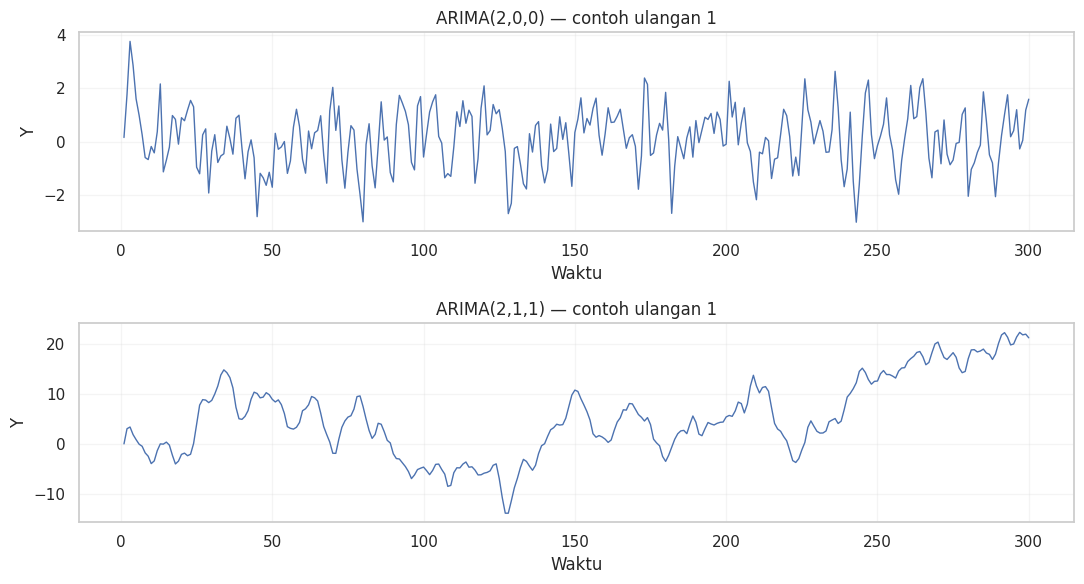

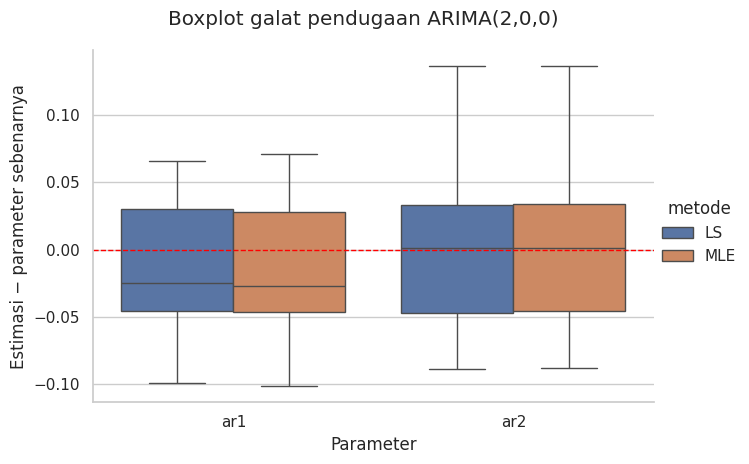

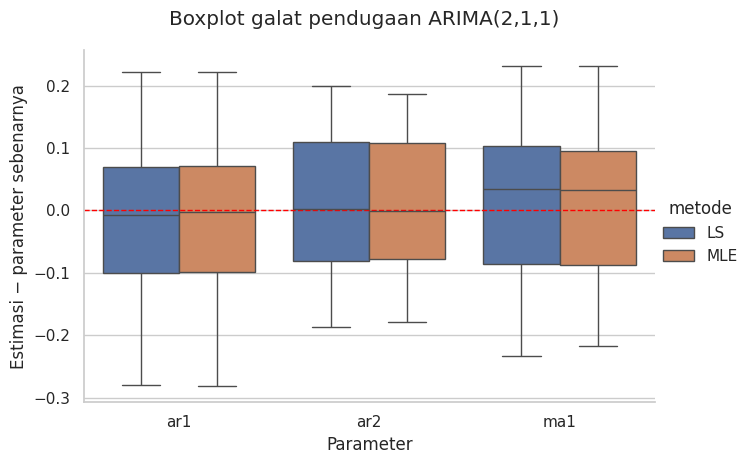

In [ ]:
fig,axes=plt.subplots(2,1,figsize=(11,6))
for ax,(nama,y) in zip(axes,contoh.items()):
    ax.plot(range(1,N+1),y,lw=1)
    ax.set(title=nama+' — contoh ulangan 1',xlabel='Waktu',ylabel='Y')
    ax.grid(alpha=.2)
plt.tight_layout();plt.savefig('kel5_deret_waktu.png',dpi=160);plt.show()

sns.set_theme(style='whitegrid')
for nama in SPESIFIKASI:
    df=hasil[hasil.model==nama]
    g=sns.catplot(data=df,x='parameter',y='penyimpangan',hue='metode',
                  kind='box',height=4.4,aspect=1.55)
    g.ax.axhline(0,color='red',linestyle='--',linewidth=1)
    g.fig.suptitle('Boxplot galat pendugaan '+nama,y=1.05)
    g.set_axis_labels('Parameter','Estimasi − parameter sebenarnya')
    g.savefig('kel5_boxplot_'+nama.replace('(','').replace(')','').replace(',','_')+'.png',dpi=180)
    plt.show()

**Visualisasi Deret Waktu**

- ARIMA(2,0,0): Fluktuasi deret bergerak stabil mengelilingi rata-rata nol dengan varians yang seragam sepanjang waktu ($t=1$ hingga $t=300$). Ini mengonfirmasi secara visual bahwa deret bersifat stasioner pada level.
- ARIMA(2,1,1): Deret memperlihatkan pergerakan stokastik acak (wandering) dan membentuk tren jangka panjang (berada pada rentang $-14$ hingga $+22$). Pola ini mengonfirmasi sifat non-stasioner pada level akibat adanya tingkat pembedaan $d=1$.

**Boxplot Galat Pendugaan ARIMA(2,0,0)**

- Kedua metode LS dan MLE tampil utuh dan menghasilkan distribusi galat yang berimpit hampir sempurna pada parameter ar1 maupun ar2.
- Median galat untuk ar1 dan ar2 berada sangat dekat dengan garis batas nol (garis merah putus-putus). Ini menandakan galat pendugaan terdistribusi seimbang mengelilingi nilai parameter asli.
- Rentang kotak kotak (IQR) dan rentang whisker sangat sempit (galat hanya berkisar di rentang $-0.10$ hingga $+0.14$). Hal ini mencerminkan presisi estimasi yang sangat tinggi dan ragam pendugaan yang kecil, baik pada metode LS maupun MLE.

**Boxplot Galat Pendugaan ARIMA(2,1,1)**
- Distribusi galat antara LS (biru) dan MLE (cokelat) secara umum sangat seimbang pada ketiga parameter (ar1, ar2, ma1). Meskipun begitu, pada parameter ma1, whisker metode MLE sedikit lebih rapat dibanding LS, mengarahkan pada presisi pendugaan yang sedikit lebih tinggi.
- Median galat ketiga parameter tetap terpusat di dekat garis nol.
- IQR dan whisker pada ARIMA(2,1,1) terlihat jauh lebih lebar (rentang galat mencapai $-0.28$ hingga $+0.23$) dibanding ARIMA(2,0,0). Hal ini sesuai dengan hasil tabel statistik sebelumnya, di mana proses pembedaan dan estimasi parameter MA menambah variabilitas galat pendugaan.

## 6. Perbandingan bias dan ragam

Bias dan ragam dari tiap parameter-metode adalah **satu angka**, sehingga lebih tepat ditampilkan sebagai tabel atau diagram batang/titik. Untuk menilai kinerja secara keseluruhan, RMSE menjadi ringkasan tambahan.

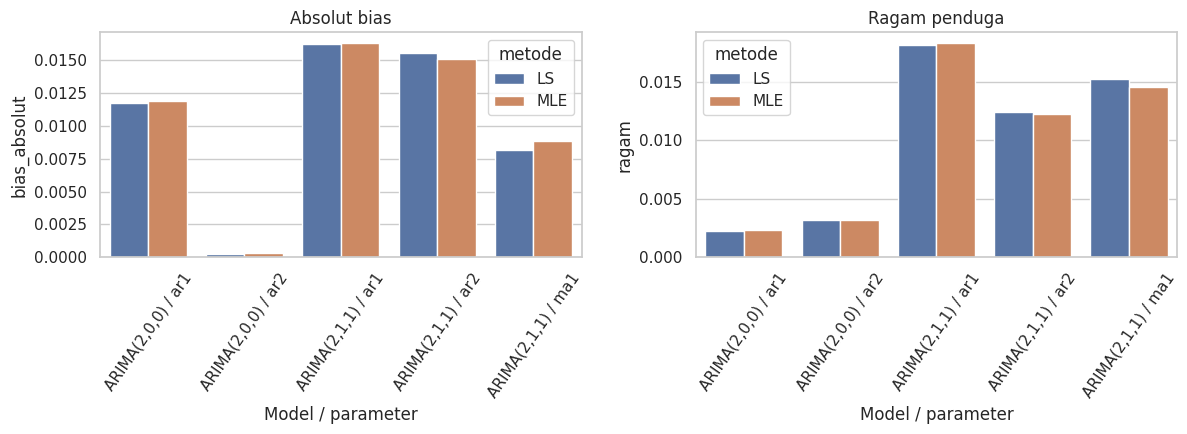

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
plotdata=evaluasi.copy()
plotdata['parameter_model']=plotdata['model']+' / '+plotdata['parameter']
sns.barplot(data=plotdata,x='parameter_model',y='bias_absolut',hue='metode',ax=axes[0])
sns.barplot(data=plotdata,x='parameter_model',y='ragam',hue='metode',ax=axes[1])
axes[0].set_title('Absolut bias');axes[1].set_title('Ragam penduga')
for ax in axes: ax.tick_params(axis='x',rotation=55);ax.set_xlabel('Model / parameter')
plt.tight_layout();plt.savefig('kel5_bias_ragam.png',dpi=180,bbox_inches='tight');plt.show()

**Evaluasi Bias Absolut**

* Model ARIMA(2,0,0): Kedua metode (LS dan MLE) menghasilkan bias absolut yang sangat rendah. Bias pada parameter ar2 berada di tingkat yang paling minimum (hampir mendekati nol). Metode LS tercatat unggul tipis dengan bias absolut yang sedikit lebih kecil pada parameter ar1.

* Model ARIMA(2,1,1): Performa bias absolut antara LS dan MLE tergolong sangat seimbang. LS menghasilkan bias yang sedikit lebih rendah pada parameter ma1, sedangkan MLE sedikit lebih unggul (bias lebih kecil) pada parameter ar2.



**Evaluasi Ragam Penduga**

* Ragam penduga pada seluruh parameter ARIMA(2,0,0) jauh lebih kecil dibandingkan ARIMA(2,1,1). Hal ini menunjukkan tingkat presisi estimasi yang jauh lebih tinggi pada model stasioner murni tanpa pembedaan.


* Pada ARIMA(2,0,0), metode LS mencatatkan nilai ragam yang sedikit lebih rendah pada kedua parameter (ar1 dan ar2).

* Pada ARIMA(2,1,1), metode MLE memperlihatkan keunggulan efisiensi yang paling terlihat pada parameter ma1, di mana batang ragam MLE berada lebih rendah dibandingkan LS.



**Kesimpulan**

* Metode LS bekerja dengan sangat presisi pada model autoregresif murni. Sementara itu, metode MLE menunjukkan keunggulan efisiensi (meminimalkan variabilitas galat) ketika memodelkan komponen Moving Average (ma1) pada deret yang melalui pembedaan.


* Peralihan dari ARIMA(2,0,0) ke ARIMA(2,1,1) secara konsisten meningkatkan bias absolut sekaligus ragam penduga pada kedua metode akibat tambahan kompleksitas proses pembedaan ($d=1$) dan parameter MA.

## 7. Simpan hasil dan pemeriksaan akhir

In [ ]:
hasil.to_csv('kel5_30_estimasi.csv',index=False)
evaluasi.to_csv('kel5_ringkasan_bias_ragam.csv',index=False)
diagnostik.to_csv('kel5_diagnostik_konvergensi.csv',index=False)
for nama, s in SPESIFIKASI.items():
    npar=len(s['true']); print(nama,'expected parameter estimates if all succeed =',B*2*npar)
print('Selesai. Untuk kesimpulan, gunakan tabel evaluasi dan konvergensi hasil eksekusi aktual.')

ARIMA(2,0,0) expected parameter estimates if all succeed = 120
ARIMA(2,1,1) expected parameter estimates if all succeed = 180
Selesai. Untuk kesimpulan, gunakan tabel evaluasi dan konvergensi hasil eksekusi aktual.
